In [ ]:
import import_ipynb
import data_analysis_regression
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import BayesianRidge
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

In [ ]:
reg_features = ['Income_Category', 'Card_Category_Blue', 'Total_Trans_Amt',
                 'Card_Category_Silver', 'Total_Trans_Ct', 'Card_Category_Gold',
                 'Dependent_count']

Xr_train = data_analysis_regression.X_train[reg_features]
Xr_test = data_analysis_regression.X_test[reg_features]
yr_train = data_analysis_regression.y_train
yr_test = data_analysis_regression.y_test


continuous_cols = ['Total_Trans_Amt', 'Total_Trans_Ct', 'Dependent_count']

scaler = StandardScaler()
Xr_train_scaled = Xr_train.copy()
Xr_test_scaled = Xr_test.copy()

Xr_train_scaled[continuous_cols] = scaler.fit_transform(Xr_train[continuous_cols])
Xr_test_scaled[continuous_cols] = scaler.transform(Xr_test[continuous_cols])

In [12]:
class BayesianLinearRegression:
    """alpha = weight prior precision, beta = noise precision.
    evidence=True เรียนรู้ทั้งสองค่าจาก marginal likelihood"""

    def __init__(self, alpha=1.0, beta=None, evidence=True, max_iter=300, tol=1e-6):
        self.alpha = alpha
        self.beta = beta
        self.evidence = evidence
        self.max_iter = max_iter
        self.tol = tol
        self.mu_post = None
        self.Sigma_post = None

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float).ravel()
        n, d = X.shape

        # center เพื่อไม่ให้ prior หด intercept
        self.x_mean_ = X.mean(axis=0)
        self.y_mean_ = y.mean()
        Xc = X - self.x_mean_
        yc = y - self.y_mean_

        if self.beta is None:
            self.beta = 1.0 / np.var(yc)

        XtX = Xc.T @ Xc
        Xty = Xc.T @ yc
        eig = np.linalg.eigvalsh(XtX)

        for _ in range(self.max_iter if self.evidence else 1):
            Sigma = np.linalg.inv(self.beta * XtX + self.alpha * np.eye(d))
            m = self.beta * Sigma @ Xty
            if not self.evidence:
                break

            lam = self.beta * eig
            gamma = np.sum(lam / (self.alpha + lam))      # effective number of parameters
            alpha_new = gamma / max(m @ m, 1e-12)
            rss = np.sum((yc - Xc @ m) ** 2)
            beta_new = (n - gamma) / max(rss, 1e-12)

            converged = (abs(alpha_new - self.alpha) < self.tol * self.alpha and
                         abs(beta_new - self.beta) < self.tol * self.beta)
            self.alpha, self.beta = alpha_new, beta_new
            if converged:
                break

        self.Sigma_post = np.linalg.inv(self.beta * XtX + self.alpha * np.eye(d))
        self.w_ = self.beta * self.Sigma_post @ Xty
        self.intercept_ = self.y_mean_ - self.x_mean_ @ self.w_
        self.mu_post = np.r_[self.intercept_, self.w_].reshape(-1, 1)
        return self

    def predict(self, X, return_std=False):
        X = np.asarray(X, dtype=float)
        y_mean = X @ self.w_ + self.intercept_
        if return_std:
            Xc = X - self.x_mean_
            var = np.sum(Xc @ self.Sigma_post * Xc, axis=1) + 1.0 / self.beta
            return y_mean, np.sqrt(var)
        return y_mean

In [13]:
model = BayesianLinearRegression()
model.fit(Xr_train_scaled.values, yr_train)

y_pred, y_std = model.predict(Xr_test_scaled.values, return_std=True)

print("alpha =", model.alpha, " beta =", model.beta)
print("95% interval coverage =", np.mean(np.abs(np.asarray(yr_test).ravel() - y_pred) <= 1.96 * y_std))

alpha = 1.7171048369931483e-08  beta = 2.6608141778898465e-08
95% interval coverage = 0.926949654491609


In [14]:
# evaluate
r2 = r2_score(yr_test, y_pred)
mse = mean_squared_error(yr_test, y_pred)
mae = mean_absolute_error(yr_test, y_pred)

print(f"R² = {r2:.4f}")
print(f"MSE = {mse:.2f}")
print(f"MAE = {mae:.2f}")

R² = 0.5386
MSE = 38195831.17
MAE = 4250.91


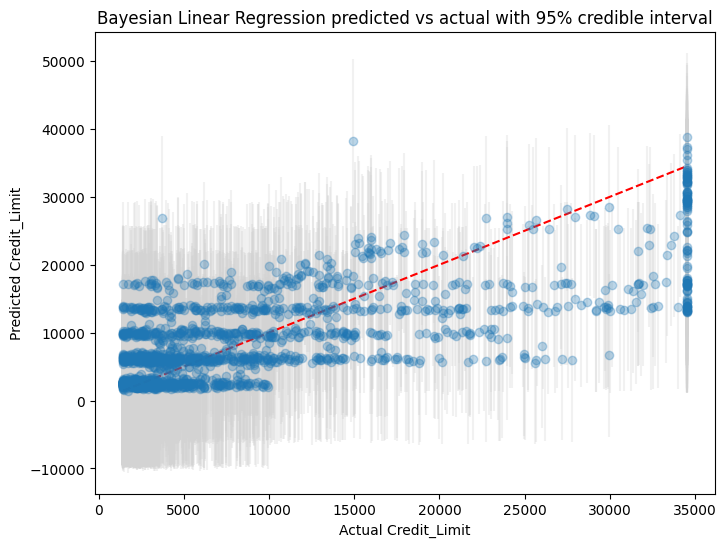

In [15]:
# plot predicted vs actual พร้อม credible interval
plt.figure(figsize=(8,6))
plt.errorbar(yr_test, y_pred, yerr=1.96*y_std, fmt='o', alpha=0.3, ecolor='lightgray')
plt.plot([yr_test.min(), yr_test.max()], [yr_test.min(), yr_test.max()], 'r--')
plt.xlabel('Actual Credit_Limit')
plt.ylabel('Predicted Credit_Limit')
plt.title('Bayesian Linear Regression predicted vs actual with 95% credible interval')
plt.show()

In [16]:
sk_model = BayesianRidge()
sk_model.fit(Xr_train_scaled.values, yr_train)
y_pred_sk = sk_model.predict(Xr_test_scaled.values)

print("sklearn R²:", r2_score(yr_test, y_pred_sk))
print("weight ของเรา:", model.mu_post.ravel())
print("weight ของ sklearn:", np.r_[sk_model.intercept_, sk_model.coef_])

sklearn R²: 0.5385679388440179
weight ของเรา: [ 21985.33549328   3691.82002689 -19298.99595591   1057.86784259
  -3522.34810658   -454.30330035   -800.66864596    221.34118172]
weight ของ sklearn: [ 21985.33524864   3691.82002683 -19298.99571075   1057.86784327
  -3522.34786117   -454.30330053   -800.66840192    221.34118176]


In [17]:
import os, pickle
os.makedirs("models", exist_ok=True)

def save_model(model, path):
    """บันทึกโมเดลที่ fit แล้ว ทั้ง hyperparameter และ parameter ที่เรียนได้ ลงไฟล์"""
    with open(path, "wb") as f:
        pickle.dump(model, f)

def load_model(path):
    with open(path, "rb") as f:
        return pickle.load(f)

def check_save_load(model, path, X_test, name):
    """save -> load -> predict บนข้อมูล test แล้วเทียบกับโมเดลต้นฉบับ  max_abs_diff ควรเป็น 0"""
    save_model(model, path)
    reloaded = load_model(path)
    diff = float(np.max(np.abs(np.asarray(model.predict(X_test)) - np.asarray(reloaded.predict(X_test)))))
    return {"model": name, "file": path, "size_kb": round(os.path.getsize(path) / 1024, 1), "max_abs_diff": diff}

In [18]:
# บันทึกโมเดล แล้วโหลดกลับมาทดสอบกับ test set
check_save_load(model, "models/bayesian.pkl", Xr_test_scaled.values, "Bayesian Linear Regression")

{'model': 'Bayesian Linear Regression',
 'file': 'models/bayesian.pkl',
 'size_kb': 1.0,
 'max_abs_diff': 0.0}